# Testing the mitigation on synthetic data sets

Test `smart_size_mitigation_heuristics.plan()` on a synthetic population of MOUSes whose size distribution follows the
Cycle 7 statistics of the ALMA mitigation memo:

> Kepley et al. 2023, *Mitigation Statistics*, ALMA Memo 623 (<https://library.nrao.edu/public/memos/alma/main/memo623.pdf>)

## 1. Size distribution from Figure 8 of Memo 623

Figure 8 of the memo shows the total product size vs. the maximum cube size of each Cycle 7 MOUS in their sample
(2565 MOUSes, 325 of them mitigated):

* **grey**: size of the delivered (i.e. mitigated, where applicable) products,
* **orange**: unmitigated size of the products.

Limits indicated in the plot: cube mitigation threshold `maxcubesize` = 40 GB, cube mitigation limit `maxcubelimit` = 60 GB,
product size limit `maxproductsize` = 350 GB.

The points below were digitised from the raster image of Figure 8 embedded in the PDF:

* Axis calibration from the major tick marks (log axes; 1 px ≈ 0.008 dex in x and 0.011 dex in y, i.e. ≈2 % precision).
* Markers were found as connected regions of the exact marker colours (grey `#d3d3d3`, orange `#ff7f0e`); regions larger
  than one marker were split into several points (k-means on the pixel positions), the legend was masked.

**Caveats**

* Overlapping markers cannot be fully separated, so dense regions (in particular the diagonal ridges) are under-represented:
  about 1085 grey points are recovered of 2565 MOUSes, and about 207 orange points of 325 mitigated MOUSes. The background colour map
  of the figure (density per bin) is not used here.
* Grey and orange points cannot be paired: it is not known which delivered size belongs to which unmitigated size.
* Some MOUSes had their mitigation limits lifted (9 %), and the product limit was raised from 350 to 500 GB between Cycle 7 and 8,
  so some grey points lie beyond the limits.


In [1]:
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from smart_size_mitigation_heuristics import (
    Limits, build_mitigation_table, plan, sizes_from_imlist, CUBE_LEVER_COLUMNS,
)

In [2]:
# Digitised from Memo 623, Figure 8. Sizes in GB, sorted by product size.
MEMO623_FIG8 = {
    "delivered": {  # grey points
        "product_size_GB": [
            0.015, 0.0158, 0.0166, 0.0194, 0.0195, 0.0208, 0.0212, 0.0214, 0.025, 0.0254,
            0.0265, 0.0267, 0.0279, 0.028, 0.0287, 0.0292, 0.0303, 0.0316, 0.032, 0.0328,
            0.0335, 0.0359, 0.0367, 0.0376, 0.0385, 0.0387, 0.0401, 0.0403, 0.0414, 0.0423,
            0.0431, 0.0463, 0.0493, 0.0493, 0.0522, 0.0522, 0.0564, 0.0571, 0.0575, 0.0597,
            0.0598, 0.0634, 0.0646, 0.0659, 0.0664, 0.0753, 0.0755, 0.0785, 0.08, 0.0916,
            0.0934, 0.095, 0.099, 0.099, 0.099, 0.0993, 0.103, 0.104, 0.113, 0.115,
            0.116, 0.116, 0.12, 0.12, 0.125, 0.125, 0.131, 0.132, 0.138, 0.14,
            0.143, 0.148, 0.157, 0.158, 0.161, 0.162, 0.163, 0.167, 0.167, 0.171,
            0.174, 0.175, 0.179, 0.18, 0.184, 0.184, 0.184, 0.184, 0.186, 0.193,
            0.195, 0.202, 0.204, 0.205, 0.208, 0.211, 0.213, 0.216, 0.222, 0.222,
            0.223, 0.225, 0.228, 0.231, 0.233, 0.235, 0.237, 0.239, 0.24, 0.245,
            0.251, 0.255, 0.258, 0.261, 0.262, 0.266, 0.268, 0.269, 0.276, 0.286,
            0.286, 0.288, 0.297, 0.305, 0.305, 0.306, 0.311, 0.317, 0.321, 0.322,
            0.323, 0.328, 0.335, 0.339, 0.343, 0.346, 0.352, 0.355, 0.355, 0.358,
            0.361, 0.378, 0.378, 0.378, 0.38, 0.393, 0.396, 0.401, 0.411, 0.419,
            0.42, 0.421, 0.426, 0.433, 0.441, 0.444, 0.445, 0.45, 0.45, 0.454,
            0.457, 0.458, 0.458, 0.462, 0.463, 0.477, 0.488, 0.491, 0.501, 0.504,
            0.508, 0.509, 0.517, 0.517, 0.525, 0.526, 0.537, 0.544, 0.546, 0.549,
            0.57, 0.572, 0.587, 0.607, 0.611, 0.613, 0.613, 0.613, 0.613, 0.621,
            0.638, 0.644, 0.65, 0.662, 0.67, 0.671, 0.676, 0.676, 0.676, 0.689,
            0.691, 0.693, 0.7, 0.703, 0.71, 0.715, 0.721, 0.734, 0.737, 0.739,
            0.742, 0.747, 0.754, 0.758, 0.767, 0.772, 0.772, 0.775, 0.777, 0.789,
            0.796, 0.8, 0.806, 0.809, 0.815, 0.818, 0.822, 0.831, 0.852, 0.853,
            0.853, 0.854, 0.856, 0.862, 0.865, 0.879, 0.887, 0.888, 0.892, 0.898,
            0.904, 0.905, 0.918, 0.924, 0.926, 0.94, 0.947, 0.955, 0.958, 0.958,
            0.977, 0.977, 0.977, 0.989, 1.01, 1.02, 1.02, 1.02, 1.02, 1.04,
            1.05, 1.07, 1.08, 1.08, 1.1, 1.12, 1.12, 1.12, 1.12, 1.16,
            1.16, 1.17, 1.17, 1.18, 1.19, 1.19, 1.2, 1.23, 1.24, 1.25,
            1.25, 1.26, 1.27, 1.27, 1.3, 1.31, 1.32, 1.32, 1.32, 1.33,
            1.34, 1.34, 1.35, 1.36, 1.37, 1.37, 1.38, 1.38, 1.39, 1.39,
            1.4, 1.41, 1.41, 1.42, 1.43, 1.44, 1.45, 1.45, 1.45, 1.45,
            1.49, 1.51, 1.52, 1.53, 1.53, 1.55, 1.57, 1.59, 1.59, 1.59,
            1.59, 1.59, 1.6, 1.6, 1.64, 1.69, 1.69, 1.7, 1.71, 1.71,
            1.73, 1.73, 1.75, 1.76, 1.81, 1.81, 1.84, 1.85, 1.85, 1.86,
            1.86, 1.87, 1.89, 1.89, 1.9, 1.91, 1.93, 1.93, 1.95, 1.96,
            1.96, 1.97, 2, 2.01, 2.01, 2.03, 2.03, 2.04, 2.04, 2.04,
            2.05, 2.09, 2.09, 2.1, 2.11, 2.12, 2.14, 2.18, 2.2, 2.21,
            2.21, 2.24, 2.28, 2.28, 2.29, 2.29, 2.3, 2.3, 2.31, 2.31,
            2.34, 2.39, 2.39, 2.41, 2.43, 2.44, 2.45, 2.46, 2.46, 2.48,
            2.52, 2.53, 2.53, 2.53, 2.55, 2.57, 2.57, 2.59, 2.63, 2.63,
            2.66, 2.66, 2.69, 2.69, 2.72, 2.73, 2.75, 2.75, 2.76, 2.78,
            2.8, 2.8, 2.8, 2.82, 2.84, 2.84, 2.85, 2.9, 2.9, 2.91,
            2.96, 2.97, 2.97, 2.98, 2.98, 3, 3.01, 3.01, 3.04, 3.05,
            3.11, 3.12, 3.13, 3.15, 3.15, 3.17, 3.21, 3.23, 3.24, 3.25,
            3.26, 3.26, 3.31, 3.32, 3.32, 3.33, 3.34, 3.37, 3.44, 3.45,
            3.46, 3.5, 3.5, 3.51, 3.54, 3.54, 3.56, 3.58, 3.59, 3.59,
            3.61, 3.65, 3.66, 3.69, 3.72, 3.73, 3.73, 3.73, 3.75, 3.77,
            3.8, 3.81, 3.86, 3.87, 3.89, 3.91, 4.05, 4.07, 4.09, 4.1,
            4.12, 4.15, 4.16, 4.16, 4.19, 4.19, 4.19, 4.21, 4.24, 4.25,
            4.27, 4.28, 4.35, 4.41, 4.41, 4.42, 4.47, 4.51, 4.54, 4.56,
            4.57, 4.58, 4.63, 4.67, 4.69, 4.7, 4.7, 4.7, 4.7, 4.79,
            4.81, 4.86, 4.88, 4.92, 4.95, 5.03, 5.05, 5.1, 5.11, 5.25,
            5.26, 5.27, 5.28, 5.28, 5.3, 5.35, 5.39, 5.39, 5.4, 5.43,
            5.44, 5.49, 5.49, 5.5, 5.5, 5.52, 5.58, 5.62, 5.62, 5.64,
            5.67, 5.74, 5.82, 5.83, 5.83, 5.84, 5.87, 5.91, 5.97, 6,
            6.01, 6.01, 6.09, 6.11, 6.19, 6.2, 6.26, 6.29, 6.31, 6.31,
            6.35, 6.41, 6.44, 6.49, 6.54, 6.56, 6.7, 6.72, 6.72, 6.73,
            6.82, 6.85, 6.86, 6.93, 6.93, 6.93, 6.98, 7, 7.07, 7.14,
            7.18, 7.2, 7.2, 7.35, 7.35, 7.35, 7.44, 7.45, 7.49, 7.49,
            7.52, 7.62, 7.64, 7.64, 7.68, 7.69, 7.72, 7.74, 8.01, 8.02,
            8.08, 8.09, 8.09, 8.15, 8.3, 8.38, 8.4, 8.54, 8.62, 8.66,
            8.75, 8.75, 8.91, 8.92, 9.09, 9.09, 9.27, 9.36, 9.45, 9.6,
            9.64, 9.64, 9.85, 10.2, 10.2, 10.5, 10.5, 10.8, 11, 11.2,
            11.3, 11.3, 11.4, 11.6, 11.7, 11.7, 11.8, 11.8, 11.9, 11.9,
            11.9, 12.1, 12.2, 12.3, 12.4, 12.4, 12.4, 12.4, 12.4, 12.6,
            12.6, 12.7, 12.9, 13, 13.1, 13.3, 13.4, 13.5, 13.7, 13.9,
            14, 14.1, 14.3, 14.3, 14.5, 14.6, 15.1, 15.2, 15.4, 15.4,
            15.4, 15.5, 15.9, 16, 16.2, 16.3, 16.6, 16.6, 17, 17,
            17.2, 17.3, 17.8, 17.8, 17.9, 18, 18.3, 18.3, 18.3, 18.4,
            18.6, 19.2, 19.3, 19.6, 19.9, 20.1, 20.7, 20.9, 20.9, 21.1,
            21.4, 21.4, 21.8, 22, 22.2, 22.4, 22.4, 22.6, 22.8, 23.1,
            23.2, 23.3, 23.5, 23.6, 23.9, 23.9, 24.6, 24.9, 25.1, 25.2,
            25.4, 26.3, 26.9, 26.9, 27.5, 27.5, 27.5, 27.5, 28.6, 28.8,
            29.1, 29.7, 30.3, 30.5, 30.6, 31.3, 31.3, 32, 32.8, 33.4,
            33.6, 33.7, 33.8, 34.4, 35.4, 35.7, 35.7, 36.9, 37.1, 37.4,
            37.5, 37.5, 37.8, 37.9, 38.2, 38.6, 39, 39.5, 39.6, 40,
            40.1, 40.6, 41.4, 42, 42.1, 42.2, 42.5, 42.6, 42.9, 44.5,
            44.5, 45.1, 45.4, 46.4, 46.8, 47, 47.3, 47.6, 47.6, 48.2,
            49.2, 49.2, 49.2, 49.3, 51.1, 51.5, 52.8, 53.1, 53.8, 55.2,
            55.8, 56.2, 56.6, 56.7, 56.9, 57.6, 57.6, 58.5, 58.5, 58.5,
            58.8, 59.4, 60.1, 60.6, 60.9, 62.1, 62.5, 62.7, 64.3, 64.5,
            64.7, 65.3, 65.8, 66.3, 67.2, 67.9, 68, 68.2, 68.4, 68.9,
            69.3, 69.7, 69.7, 70.3, 70.4, 70.8, 71.1, 71.1, 71.3, 72,
            72.5, 72.5, 72.5, 72.9, 73.9, 73.9, 74, 74.6, 74.7, 75.3,
            75.3, 75.3, 76.8, 76.8, 77, 77, 78, 78.6, 79.1, 79.3,
            81.4, 81.6, 82.4, 83, 83.3, 83.7, 84.8, 85, 86.3, 86.9,
            88, 88.3, 88.5, 89.2, 89.7, 89.7, 91.5, 92.2, 93.3, 93.3,
            95, 95.2, 95.3, 96.2, 97.2, 97.6, 97.6, 98.1, 101, 101,
            101, 102, 102, 102, 103, 103, 103, 105, 105, 107,
            107, 108, 108, 109, 109, 110, 111, 111, 111, 112,
            113, 113, 115, 116, 117, 117, 118, 120, 121, 122,
            123, 125, 125, 125, 126, 127, 127, 127, 127, 128,
            128, 129, 129, 129, 131, 132, 132, 132, 132, 132,
            134, 135, 135, 135, 136, 137, 137, 139, 140, 140,
            141, 143, 144, 144, 145, 146, 146, 146, 146, 146,
            148, 148, 150, 151, 151, 154, 154, 156, 156, 157,
            157, 157, 159, 159, 160, 160, 161, 162, 163, 164,
            167, 167, 168, 168, 169, 169, 171, 173, 174, 176,
            177, 177, 179, 179, 184, 187, 187, 187, 191, 192,
            195, 199, 202, 203, 205, 207, 207, 208, 215, 215,
            215, 216, 218, 219, 220, 222, 224, 226, 228, 229,
            232, 234, 236, 237, 237, 241, 245, 250, 251, 253,
            256, 257, 259, 261, 261, 268, 271, 280, 282, 287,
            290, 292, 299, 299, 304, 304, 307, 308, 309, 310,
            310, 312, 319, 322, 326, 327, 328, 331, 332, 332,
            335, 337, 339, 342, 342, 342, 342, 343, 343, 345,
            349, 349, 349, 349, 351, 352, 352, 354, 354, 356,
            363, 366, 407, 415, 420, 445, 449, 449, 473, 476,
            495, 495, 514, 545, 803,
        ],
        "cube_size_GB": [
            0.0025, 0.00266, 0.00207, 0.00328, 0.0025, 0.00272, 0.00254, 0.00362, 0.00409, 0.00324,
            0.00534, 0.00334, 0.00466, 0.0037, 0.00498, 0.00356, 0.00495, 0.00536, 0.00403, 0.00649,
            0.00414, 0.00723, 0.00478, 0.00683, 0.0063, 0.00464, 0.00504, 0.00656, 0.00829, 0.00536,
            0.00717, 0.00932, 0.0101, 0.00829, 0.00328, 0.00649, 0.00936, 0.00709, 0.00362, 0.00748,
            0.00251, 0.00789, 0.0132, 0.00409, 0.00836, 0.00932, 0.00473, 0.0332, 0.0101, 0.026,
            0.019, 0.0393, 0.00409, 0.0287, 0.0168, 0.0426, 0.026, 0.0132, 0.00473, 0.0384,
            0.0145, 0.0332, 0.0508, 0.00251, 0.0396, 0.0522, 0.0372, 0.0164, 0.0582, 0.0267,
            0.00589, 0.0191, 0.0187, 0.0657, 0.0309, 0.0203, 0.0393, 0.0106, 0.0554, 0.0215,
            0.0427, 0.039, 0.0752, 0.0233, 0.0303, 0.00328, 0.0323, 0.0353, 0.022, 0.024,
            0.0385, 0.0249, 0.036, 0.0486, 0.0265, 0.0403, 0.0342, 0.0516, 0.0563, 0.0436,
            0.0368, 0.0288, 0.104, 0.0394, 0.00362, 0.0552, 0.0462, 0.0309, 0.0285, 0.0423,
            0.0493, 0.0318, 0.0459, 0.0164, 0.0421, 0.00409, 0.0336, 0.0639, 0.0447, 0.0656,
            0.0705, 0.133, 0.0374, 0.0846, 0.0669, 0.0764, 0.0407, 0.061, 0.0736, 0.0382,
            0.0204, 0.151, 0.0422, 0.0584, 0.0947, 0.0812, 0.146, 0.0443, 0.0582, 0.0773,
            0.0223, 0.0236, 0.162, 0.0468, 0.074, 0.11, 0.0494, 0.025, 0.0534, 0.0694,
            0.0263, 0.0346, 0.0497, 0.0573, 0.0366, 0.0678, 0.0531, 0.192, 0.125, 0.062,
            0.103, 0.0287, 0.114, 0.0388, 0.0567, 0.0655, 0.0588, 0.111, 0.142, 0.0422,
            0.0619, 0.117, 0.0332, 0.135, 0.0799, 0.066, 0.0447, 0.0715, 0.0332, 0.13,
            0.0692, 0.0352, 0.077, 0.0383, 0.0718, 0.0254, 0.152, 0.14, 0.222, 0.104,
            0.0789, 0.0396, 0.124, 0.0862, 0.279, 0.16, 0.0428, 0.0554, 0.104, 0.0657,
            0.293, 0.0383, 0.0829, 0.17, 0.0921, 0.0457, 0.117, 0.306, 0.0433, 0.0306,
            0.17, 0.0892, 0.0983, 0.122, 0.0416, 0.216, 0.0474, 0.0323, 0.132, 0.192,
            0.0951, 0.335, 0.0513, 0.106, 0.0443, 0.0336, 0.229, 0.17, 0.352, 0.205,
            0.0509, 0.101, 0.24, 0.0352, 0.111, 0.0553, 0.284, 0.208, 0.17, 0.247,
            0.0225, 0.373, 0.124, 0.111, 0.0583, 0.0194, 0.393, 0.0393, 0.00409, 0.0634,
            0.147, 0.159, 0.0707, 0.119, 0.131, 0.239, 0.284, 0.0424, 0.064, 0.0254,
            0.438, 0.0661, 0.141, 0.129, 0.173, 0.191, 0.464, 0.22, 0.0693, 0.15,
            0.134, 0.227, 0.489, 0.248, 0.0723, 0.192, 0.0792, 0.146, 0.159, 0.051,
            0.0867, 0.0743, 0.237, 0.105, 0.0802, 0.172, 0.254, 0.552, 0.0538, 0.0579,
            0.16, 0.0911, 0.221, 0.579, 0.1, 0.107, 0.084, 0.64, 0.497, 0.284,
            0.18, 0.0582, 0.336, 0.236, 0.17, 0.0445, 0.268, 0.0945, 0.3, 0.596,
            0.189, 0.288, 0.356, 0.634, 0.245, 0.0726, 0.193, 0.0515, 0.337, 0.0394,
            0.0656, 0.3, 0.672, 0.209, 0.101, 0.324, 0.202, 0.274, 0.225, 0.107,
            0.356, 0.295, 0.118, 0.0737, 0.343, 0.214, 0.112, 0.791, 0.0254, 0.233,
            0.077, 0.298, 0.44, 0.881, 0.377, 0.123, 0.77, 0.251, 0.27, 0.832,
            0.0856, 0.0799, 0.328, 0.238, 0.114, 0.126, 0.912, 0.485, 0.0424, 0.104,
            0.39, 0.285, 0.851, 0.979, 0.26, 0.0665, 0.137, 0.298, 0.0552, 0.44,
            0.366, 0.929, 0.146, 0.274, 0.0479, 0.0947, 0.383, 0.132, 0.0587, 0.334,
            0.303, 1.11, 0.987, 0.143, 0.383, 0.156, 0.348, 0.287, 0.857, 0.179,
            0.317, 0.589, 1.11, 0.904, 0.0522, 0.0794, 0.0393, 0.442, 1.21, 0.663,
            0.0856, 1.07, 0.0426, 0.963, 0.329, 0.428, 0.471, 0.12, 0.359, 0.705,
            1.31, 0.113, 0.651, 0.0837, 0.0294, 1.16, 0.0901, 0.233, 0.0254, 0.489,
            0.45, 0.737, 1.26, 0.385, 0.349, 0.074, 1.4, 0.124, 0.511, 0.0944,
            0.184, 0.427, 0.169, 0.196, 0.0787, 0.48, 0.734, 0.829, 0.384, 0.526,
            0.0989, 1.35, 0.107, 0.0515, 0.137, 0.568, 0.938, 0.427, 0.0856, 1.56,
            0.527, 0.82, 0.0624, 0.106, 0.475, 0.578, 0.903, 0.151, 0.431, 0.993,
            0.0911, 0.179, 0.509, 0.704, 0.0662, 0.631, 0.859, 0.118, 0.589, 1.7,
            0.0294, 0.74, 0.466, 1.08, 0.512, 1.8, 0.773, 0.101, 0.285, 0.126,
            0.5, 1.86, 0.136, 0.0712, 0.0515, 0.0652, 0.665, 0.0757, 0.556, 1.16,
            1.01, 0.263, 2.01, 0.523, 0.133, 0.178, 1.23, 0.765, 0.894, 0.558,
            0.829, 0.114, 1.89, 0.609, 0.738, 1.08, 0.371, 0.0839, 0.192, 0.12,
            0.896, 0.577, 1.35, 0.794, 0.974, 0.622, 0.125, 0.684, 1.23, 0.944,
            0.859, 0.212, 0.328, 0.0743, 1.12, 2.29, 0.167, 0.646, 0.179, 0.139,
            0.115, 2.13, 1.18, 1.3, 0.194, 0.231, 0.7, 1.97, 0.13, 0.886,
            1.09, 0.118, 0.0902, 0.98, 0.24, 1.41, 0.144, 0.743, 2.58, 1.33,
            0.125, 0.0582, 0.253, 0.374, 0.155, 2.47, 1.11, 0.197, 0.816, 0.393,
            0.0721, 0.766, 0.931, 0.136, 0.0582, 2.35, 0.41, 1.08, 0.122, 0.0746,
            0.926, 0.834, 0.142, 0.509, 1.56, 0.0332, 2.22, 2.45, 0.192, 0.116,
            0.129, 0.152, 0.0515, 0.298, 0.228, 0.869, 0.139, 1.3, 0.114, 1.76,
            0.954, 1.4, 0.473, 2.09, 1.21, 1.52, 1.09, 0.162, 0.133, 0.144,
            0.983, 1.48, 0.336, 0.172, 1.09, 1.43, 0.155, 0.143, 0.131, 1.03,
            0.12, 1.81, 1.14, 0.277, 0.192, 2.54, 0.38, 1.07, 0.078, 1.18,
            0.151, 0.0657, 1.27, 0.561, 2.42, 1.25, 1.37, 1.77, 0.38, 1.36,
            0.277, 0.233, 1.66, 2.35, 0.485, 0.38, 1.56, 1.44, 1.71, 1.99,
            0.983, 0.194, 0.849, 2.43, 0.179, 0.38, 3.49, 0.589, 0.167, 0.0394,
            0.104, 1.62, 1.52, 2.14, 4.34, 0.273, 0.56, 1.7, 2.26, 2.05,
            1.88, 1.55, 2.32, 2.57, 0.151, 1.74, 2.42, 1.89, 1.09, 1,
            0.934, 2.58, 2.07, 0.864, 1.92, 0.665, 0.104, 1.68, 0.209, 2.05,
            7.25, 2.23, 0.201, 3.99, 3.57, 3.32, 0.0225, 2.26, 2.92, 0.19,
            3.73, 3.11, 2.52, 2.34, 0.192, 7.43, 2.55, 0.0799, 0.133, 5.05,
            0.534, 0.298, 2.77, 1.38, 1.85, 4.89, 0.104, 1.22, 2.9, 0.116,
            2.64, 1.42, 0.0194, 0.44, 0.104, 3.11, 2.92, 2.36, 0.44, 3.29,
            10.4, 3.15, 0.0375, 4.34, 6.42, 0.38, 0.133, 3.46, 0.0236, 3.68,
            0.192, 2.42, 7.07, 3.63, 3.93, 4.52, 0.115, 4.26, 3.92, 0.0657,
            0.115, 0.349, 0.385, 4.3, 5.68, 0.363, 7.99, 4.55, 4.97, 0.387,
            0.133, 1.99, 0.349, 6.23, 1.19, 1.62, 0.104, 17.9, 4.84, 6.56,
            0.38, 1.52, 1.72, 5.12, 0.44, 17.9, 2.66, 5.48, 9.47, 0.0944,
            17.9, 2.75, 5.66, 1.94, 0.1, 0.107, 10.7, 7.67, 6.02, 1.19,
            0.509, 9.47, 1.52, 8.02, 0.104, 8.46, 12.4, 0.44, 6.67, 0.115,
            2.39, 7.07, 12.3, 9.33, 13.4, 11.4, 8.68, 29.4, 0.38, 1.45,
            14.5, 7.34, 9.76, 31.6, 0.133, 7.77, 29.6, 0.442, 2.66, 1.76,
            32.6, 8.09, 5.41, 0.426, 28.1, 24.9, 35.3, 0.449, 2.87, 30.4,
            8.3, 23.2, 14, 8.88, 32.8, 28.3, 4.45, 5.96, 21.4, 0.654,
            0.599, 0.104, 35.8, 0.695, 17, 0.305, 0.439, 30.5, 9.71, 38,
            9.06, 3.17, 0.133, 12.4, 6.27, 27.1, 34.3, 40.8, 9.95, 28.1,
            0.336, 3.33, 38.5, 0.277, 14, 34.7, 10.5, 12.2, 2.42, 43.7,
            14, 31.9, 39.4, 11.9, 35.8, 1.85, 17.9, 46.1, 21.7, 13.9,
            41.7, 37.5, 12.3, 11.5, 48.4, 14.4, 2.07, 16, 1.56, 13.4,
            1.98, 12.3, 43.6, 39.2, 17, 4.91, 51.3, 2.2, 1.84, 13,
            4.44, 46.6, 16.8, 54.5, 42.3, 15.4, 13.9, 0.38, 6.9, 57,
            50.4, 0.665, 0.959, 16.5, 46.7, 14.4, 19.7, 0.133, 0.552, 17.3,
            0.959, 0.576, 31.5, 28.8, 18.1, 64.3, 0.635, 7.99, 5.03, 21.7,
            15.8, 53.2, 2.7, 59.9, 35.7, 2.48, 3.59, 4.34, 0.429, 2.31,
            38.9, 0.789, 21.6, 3.29, 0.668, 16.9, 56.6, 36.3, 5.48, 0.94,
            5.91, 0.133, 20.1, 34, 8.52, 17.7, 14.3, 0.179, 60.4, 0.861,
            24.1, 0.944, 37.1, 9.04, 9.73, 18.7, 6.11, 78.3, 0.964, 40.5,
            23.8, 1.08, 2.92, 36, 20, 26.2, 0.534, 9.95, 83, 2.78,
            1.72, 40.7, 27.9, 21.1, 77.7, 30.9, 36.6, 87, 2.66, 23.6,
            29.1, 3.66, 21.7, 39.1, 91.1, 0.473, 0.936, 78.9, 22.4, 24.2,
            97.8, 3.49, 26, 33.6, 0.716, 45.1, 98.6, 24.3, 0.561, 109,
            3.32, 53, 26.6, 9.02, 98.5, 28.6, 90.4, 56.2, 14, 39.1,
            2.62, 30.2, 36.7, 27.9, 2.4, 32.8, 40.8, 30.4, 3.09, 35.3,
            1.06, 2.42, 42.4, 0.589, 16.2, 38.2, 0.789, 2.67, 0.497, 35,
            38.4, 8.99, 1.85, 1.25, 49.5, 2.67, 9.56, 0.591, 7.91, 19.1,
            4.79, 38, 53, 8.23, 20.4, 0.716, 0.559, 2.19, 7.54, 2.92,
            6.83, 0.611, 55, 3.52, 28.4, 1.56, 2.63, 2.39, 3.21, 8.56,
            0.959, 1.19, 1.85, 21.7, 0.716, 0.56, 2.13, 3.03, 7.27, 176,
            35.3, 8.85, 10.2, 68.2, 11.1, 10.9, 225, 56.1, 63.4, 14,
            6.11, 7.07, 63.4, 71.6, 98.3,
        ],
    },
    "unmitigated": {  # orange points
        "product_size_GB": [
            134, 145, 181, 202, 226, 237, 268, 271, 273, 324,
            340, 343, 355, 363, 367, 372, 373, 375, 379, 385,
            397, 414, 415, 415, 418, 422, 423, 423, 432, 432,
            458, 458, 476, 493, 501, 535, 545, 565, 573, 581,
            589, 612, 618, 624, 624, 624, 639, 647, 649, 674,
            674, 676, 683, 701, 715, 715, 716, 746, 755, 796,
            835, 851, 851, 861, 868, 920, 956, 956, 964, 994,
            994, 1.02e+03, 1.05e+03, 1.05e+03, 1.1e+03, 1.13e+03, 1.14e+03, 1.15e+03, 1.16e+03, 1.16e+03,
            1.19e+03, 1.2e+03, 1.21e+03, 1.25e+03, 1.26e+03, 1.28e+03, 1.28e+03, 1.32e+03, 1.34e+03, 1.36e+03,
            1.38e+03, 1.42e+03, 1.47e+03, 1.49e+03, 1.57e+03, 1.58e+03, 1.65e+03, 1.68e+03, 1.71e+03, 1.71e+03,
            1.71e+03, 1.72e+03, 1.73e+03, 1.73e+03, 1.78e+03, 1.81e+03, 1.82e+03, 1.85e+03, 1.96e+03, 2e+03,
            2.02e+03, 2.04e+03, 2.04e+03, 2.04e+03, 2.11e+03, 2.17e+03, 2.18e+03, 2.18e+03, 2.24e+03, 2.26e+03,
            2.33e+03, 2.34e+03, 2.36e+03, 2.37e+03, 2.42e+03, 2.42e+03, 2.43e+03, 2.47e+03, 2.53e+03, 2.62e+03,
            2.68e+03, 2.78e+03, 2.83e+03, 2.97e+03, 2.97e+03, 3.01e+03, 3.06e+03, 3.13e+03, 3.15e+03, 3.15e+03,
            3.25e+03, 3.33e+03, 3.34e+03, 3.48e+03, 3.49e+03, 3.51e+03, 3.53e+03, 3.59e+03, 3.74e+03, 3.81e+03,
            3.87e+03, 3.94e+03, 4.02e+03, 4.07e+03, 4.1e+03, 4.19e+03, 4.25e+03, 4.37e+03, 4.44e+03, 4.56e+03,
            4.59e+03, 4.83e+03, 4.88e+03, 4.95e+03, 4.95e+03, 5.01e+03, 5.02e+03, 5.17e+03, 5.17e+03, 5.32e+03,
            5.52e+03, 5.7e+03, 5.76e+03, 5.78e+03, 6.04e+03, 6.22e+03, 6.28e+03, 6.4e+03, 6.55e+03, 6.76e+03,
            7.19e+03, 7.24e+03, 7.48e+03, 7.48e+03, 7.83e+03, 7.85e+03, 8.18e+03, 8.32e+03, 8.65e+03, 9.09e+03,
            9.25e+03, 9.67e+03, 1.06e+04, 1.1e+04, 1.15e+04, 1.19e+04, 1.24e+04, 1.32e+04, 1.36e+04, 1.45e+04,
            1.59e+04, 1.69e+04, 1.69e+04, 1.86e+04, 2.09e+04, 2.3e+04, 2.74e+04,
        ],
        "cube_size_GB": [
            43.4, 41.6, 43.6, 49.7, 44.9, 64.9, 32.3, 63.4, 8.5, 42.7,
            40.4, 44.9, 58.8, 71.6, 42, 2.39, 46.7, 1.27, 9.6, 2.61,
            48.6, 96.9, 1.56, 25.7, 51.4, 89.1, 1.85, 83.2, 0.959, 2.94,
            0.716, 2.2, 77, 57.3, 9.06, 8.65, 87, 8.59, 2.14, 69.4,
            1.19, 2.19, 80.1, 101, 87.7, 56.1, 75.6, 2.2, 294, 47.3,
            149, 82.1, 110, 1.56, 35.3, 87, 116, 92.2, 121, 126,
            34.5, 349, 3.49, 108, 53.4, 114, 394, 7.99, 121, 24.5,
            61.9, 126, 479, 176, 394, 28.2, 6.11, 144, 7.25, 36.2,
            29.7, 501, 149, 30.9, 158, 34.5, 531, 165, 557, 225,
            38, 585, 181, 3.09, 227, 7.99, 215, 68.2, 29.9, 7.39,
            6.93, 8.07, 716, 206, 27.6, 358, 226, 445, 301, 902,
            7.23, 47.3, 32, 168, 259, 7.44, 983, 478, 275, 1.06e+03,
            526, 491, 971, 49, 45.1, 1.09e+03, 42, 308, 1.17e+03, 326,
            1.09e+03, 3.09, 348, 370, 1.36e+03, 441, 12.4, 426, 389, 1.41e+03,
            8.59, 402, 481, 545, 430, 690, 470, 573, 448, 599,
            480, 8.59, 6.9, 506, 971, 667, 544, 682, 529, 636,
            571, 604, 29.8, 680, 811, 561, 752, 128, 626, 707,
            656, 349, 768, 706, 8.59, 763, 27.7, 23.9, 831, 797,
            1.4e+03, 955, 1.01e+03, 1.18e+03, 956, 489, 1.02e+03, 505, 1.05e+03, 1.13e+03,
            32, 1.18e+03, 35.3, 690, 1.4e+03, 42.9, 2.02e+03, 1.64e+03, 27.7, 32,
            491, 34.5, 2.07e+03, 2.31e+03, 2.57e+03, 2.84e+03, 29.8,
        ],
    },
}

# Limits indicated in Figure 8 (Cycle 7 pipeline)
MEMO623_LIMITS = Limits(maxcubesize=40.0, maxproductsize=350.0, maxcubelimit=60.0)

In [3]:
memo_sizes = pd.concat(
    [pd.DataFrame(v).assign(sample=k) for k, v in MEMO623_FIG8.items()],
    ignore_index=True,
)
print(memo_sizes.groupby("sample").size())
memo_sizes.groupby("sample")[["product_size_GB", "cube_size_GB"]].describe().T

sample
delivered      1085
unmitigated     207
dtype: int64


sample                   delivered   unmitigated
product_size_GB count  1085.000000    207.000000
                mean     53.135335   3356.743961
                std      95.694665   4306.340951
                min       0.015000    134.000000
                25%       1.170000    679.500000
                50%       5.820000   1730.000000
                75%      66.300000   4145.000000
                max     803.000000  27400.000000
cube_size_GB    count  1085.000000    207.000000
                mean      6.510185    358.249831
                std      16.891735    485.338793
                min       0.002070      0.716000
                25%       0.094500     33.400000
                50%       0.440000    121.000000
                75%       2.670000    537.500000
                max     225.000000   2840.000000

Check: the digitised points reproduce Figure 8.

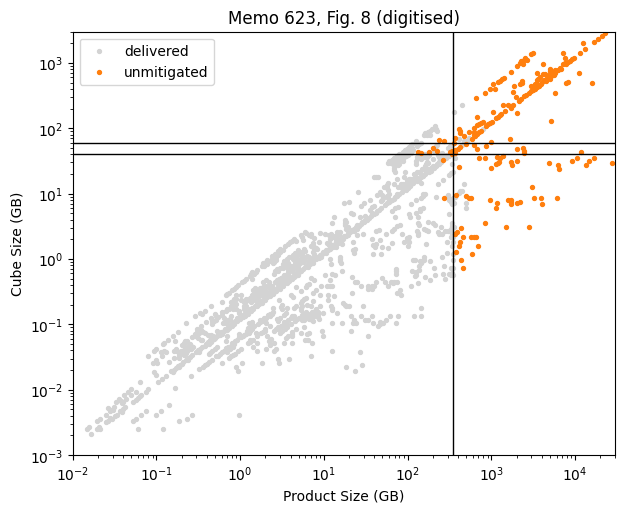

In [4]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for sample, color in [("delivered", "lightgrey"), ("unmitigated", "tab:orange")]:
    d = memo_sizes[memo_sizes["sample"] == sample]
    ax.scatter(d["product_size_GB"], d["cube_size_GB"], s=8, color=color, label=sample)
ax.axhline(MEMO623_LIMITS.maxcubesize, color="k", lw=1)
ax.axhline(MEMO623_LIMITS.maxcubelimit, color="k", lw=1)
ax.axvline(MEMO623_LIMITS.maxproductsize, color="k", lw=1)
ax.set(xscale="log", yscale="log", xlim=(1e-2, 3e4), ylim=(1e-3, 3e3),
       xlabel="Product Size (GB)", ylabel="Cube Size (GB)",
       title="Memo 623, Fig. 8 (digitised)")
ax.legend()
plt.show()

## 2. Synthetic MOUS population

Each digitised point becomes one synthetic MOUS whose **unmitigated** sizes, computed by the planner itself
(`calculate_sizes()`), reproduce the point:

* **orange** points (unmitigated sizes of mitigated MOUSes): all of them;
* **grey** points (delivered sizes): only those within the limits (cube ≤ `maxcubesize`, product ≤ `maxproductsize`).
  For an unmitigated MOUS the delivered size is the unmitigated size, so these act as the "no mitigation needed" part of the
  population. Grey points beyond the limits are deliverables of mitigated MOUSes (limits lifted) and are left out.
  The mitigated deliverables that do lie within the limits cannot be told apart and stay in.

Figure 8 only fixes two numbers per MOUS. Everything else (number of spws, channels per spw, mosaic or not, robust) is drawn from the
priors below; the PB level at the image edge and the pixels per beam are the pipeline defaults (0.2 and 5), then the image size and the number of fields are solved for so
that the sizes match. With `n` the image size (the same for all spws and fields):

* the maximum cube is $C = 4\,n^2 \max(n_\mathrm{chan}) / 10^9$ GB, which gives `n`;
* the total product is $P = n_\mathrm{fields} \cdot 8\,n^2 (n_\mathrm{spw} + \sum n_\mathrm{chan}) / 10^9$ GB, which gives `nfields`
  (an integer ≥ 1).

Since `nfields` is rounded, $P$ is not reproduced exactly for MOUSes with few fields; of `N_TRIES` drawn spw setups the
best-matching one is kept.

In [5]:
# Priors of the MOUS properties that Figure 8 does not constrain. All of them are
# assumptions; change them here.
PRIORS = {
    # number of science spws per MOUS
    "nspw": {1: 0.05, 2: 0.05, 3: 0.05, 4: 0.75, 6: 0.10},
    # channels per spw (only these values matter for the n_bin lever)
    "nchan": {128: 0.25, 240: 0.05, 480: 0.10, 960: 0.15, 1920: 0.25, 3840: 0.15, 7680: 0.05},
    "p_ratio_satisfied": 0.5,  # channel-width ratio condition for n_bin (nchan 480-1920)
    "p_mosaic": 0.25,  # PB lever not available for mosaics
    "pb": 0.2,  # PB response at the image edge: pipeline default (mitigation raises it to 0.7)
    "ppb": 5.0,  # pixels per beam: pipeline default (mitigation lowers it to 3.0 / 3.25)
    "p_robust2": 0.1,  # robust = 2.0 (cell floor 3.25), else 0.5
}
N_TRIES = 50  # spw setups drawn per MOUS; the one matching the product size best is kept
SEED = 42


def _draw(rng, prior):
    keys = list(prior)
    return keys[rng.choice(len(keys), p=np.array(list(prior.values())) / sum(prior.values()))]


def make_mous(product_GB, cube_GB, rng, priors=PRIORS, n_tries=N_TRIES):
    """One synthetic MOUS whose UNMITIGATED total product size and maximum cube
    size reproduce (product_GB, cube_GB), with calculate_sizes():

        max cube       C = 4 n^2 max(nchan) / 1e9
        total product  P = nfields * 8 n^2 (nspw + sum(nchan)) / 1e9

    (n = imsize, the same for all spws and fields). The spw setup (nspw, nchan) is
    drawn from the priors; n follows from C, and nfields from P/C, rounded to an
    integer >= 1. Of n_tries setups the one that reproduces P best is kept."""
    best = None
    for _ in range(n_tries):
        nspw = _draw(rng, priors["nspw"])
        nchan = [_draw(rng, priors["nchan"]) for _ in range(nspw)]
        per_field_ratio = 2 * (nspw + sum(nchan)) / max(nchan)  # P / C for one field
        nfields = max(1, round(product_GB / (cube_GB * per_field_ratio)))
        mismatch = abs(math.log(nfields * per_field_ratio * cube_GB / product_GB))
        if best is None or mismatch < best[0]:
            best = (mismatch, nchan, nfields)
        if mismatch < math.log(1.05):
            break
    _, nchan, nfields = best
    n = max(1, round(math.sqrt(cube_GB * 1e9 / (4 * max(nchan)))))

    spws = [str(25 + 2 * i) for i in range(len(nchan))]
    is_mosaic = bool(rng.random() < priors["p_mosaic"])
    robust = 2.0 if rng.random() < priors["p_robust2"] else 0.5
    spw_rows = [
        {
            "spw": spw,
            "nchan": nc,
            "ratio_satisfied": bool(rng.random() < priors["p_ratio_satisfied"]),
            "pb": priors["pb"],
            "is_mosaic": is_mosaic,
            "ppb": priors["ppb"],
            "robust": robust,
        }
        for spw, nc in zip(spws, nchan)
    ]
    imlist = [
        {"field": f"f{i}", "spw": spw, "imsize": (n, n), "nbin": -1, "specmode": "cube"}
        for i in range(nfields)
        for spw in spws
    ]
    return {
        "spw_rows": spw_rows,
        "imlist": imlist,
        "nchan": dict(zip(spws, nchan)),
        "repr_spw": str(rng.choice(spws)),
        "nfields": nfields,
    }


In [6]:
rng = np.random.default_rng(SEED)
limits = MEMO623_LIMITS

population = []
for source, sample in [("orange", "unmitigated"), ("grey", "delivered")]:
    d = MEMO623_FIG8[sample]
    for P, Cb in zip(d["product_size_GB"], d["cube_size_GB"]):
        if source == "grey" and not (Cb <= limits.maxcubesize and P <= limits.maxproductsize):
            continue
        mous = make_mous(P, Cb, rng)
        cube_sizes, product_sizes, _ = sizes_from_imlist(mous["imlist"], mous["nchan"].__getitem__)
        mous.update(
            source=source,
            target_product_GB=P,
            target_cube_GB=Cb,
            product_GB=sum(product_sizes.values()),
            cube_GB=max(cube_sizes.values()),
        )
        population.append(mous)

pop = pd.DataFrame(
    {
        "source": m["source"],
        "target_product_GB": m["target_product_GB"],
        "target_cube_GB": m["target_cube_GB"],
        "product_GB": m["product_GB"],
        "cube_GB": m["cube_GB"],
        "nspw": len(m["nchan"]),
        "nfields": m["nfields"],
        "is_mosaic": m["spw_rows"][0]["is_mosaic"],
        "repr_nchan": m["nchan"][m["repr_spw"]],
    }
    for m in population
)
print(pop.groupby("source").size())
pop.groupby("source")[["nspw", "nfields", "repr_nchan", "product_GB", "cube_GB"]].describe().T.round(2)

source
grey      1025
orange     207
dtype: int64


source               grey    orange
nspw       count  1025.00    207.00
           mean      3.66      3.67
           std       1.24      1.25
           min       1.00      1.00
           25%       4.00      4.00
           50%       4.00      4.00
           75%       4.00      4.00
           max       6.00      6.00
nfields    count  1025.00    207.00
           mean     12.40     22.66
           std      31.53     45.52
           min       1.00      1.00
           25%       1.00      2.00
           50%       3.00      3.00
           75%       8.00     15.00
           max     314.00    252.00
repr_nchan count  1025.00    207.00
           mean   1603.90   1721.66
           std    1963.90   2051.53
           min     128.00    128.00
           25%     128.00    128.00
           50%     960.00    960.00
           75%    1920.00   1920.00
           max    7680.00   7680.00
product_GB count  1025.00    207.00
           mean     40.92   3364.16
           std      75.07   4330.49
           min       0.01    130.26
           25%       1.04    688.10
           50%       4.90   1717.61
           75%      43.78   4056.41
           max     357.96  27358.11
cube_GB    count  1025.00    207.00
           mean      3.66    358.25
           std       8.12    485.35
           min       0.00      0.72
           25%       0.08     33.39
           50%       0.38    121.03
           75%       2.07    537.54
           max      39.42   2840.15

Check: how well the synthetic MOUSes reproduce the digitised sizes.

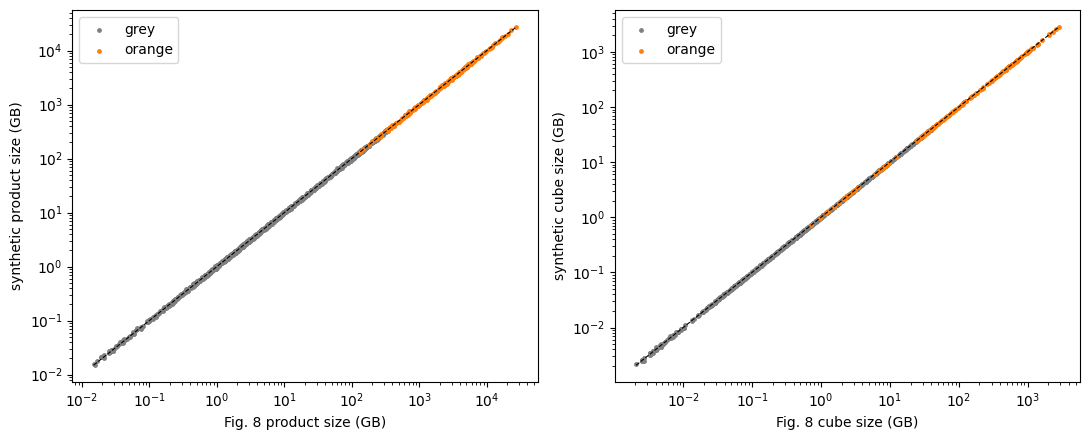

product size, synthetic/target: median 1.001, 16-84% range 0.972-1.033


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, q in zip(axes, ["product", "cube"]):
    for source, color in [("grey", "grey"), ("orange", "tab:orange")]:
        d = pop[pop["source"] == source]
        ax.scatter(d[f"target_{q}_GB"], d[f"{q}_GB"], s=6, color=color, label=source)
    lim = [pop[[f"target_{q}_GB", f"{q}_GB"]].min().min(), pop[[f"target_{q}_GB", f"{q}_GB"]].max().max()]
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set(xscale="log", yscale="log", xlabel=f"Fig. 8 {q} size (GB)", ylabel=f"synthetic {q} size (GB)")
    ax.legend()
plt.tight_layout()
plt.show()

ratio = np.log10(pop["product_GB"] / pop["target_product_GB"])
print(f"product size, synthetic/target: median {10**ratio.median():.3f}, "
      f"16-84% range {10**ratio.quantile(0.16):.3f}-{10**ratio.quantile(0.84):.3f}")

## 3. Running `plan()` on every MOUS

The limits are those of Figure 8 (`MEMO623_LIMITS`). `plan()` raises a `ValueError` when a MOUS has more than
`max_candidates` (1,000,000) plans to enumerate; such MOUSes are recorded as `error`.

Mitigation types follow the categories of the memo's table "Types of Mitigation Done":
cube-size levers (n_bin, PB, cell, ROI), removing spws, removing fields.

In [8]:
def mitigation_type(final, nfields):
    """The memo's mitigation categories: which of cube levers / spws / fields were used."""
    kept = final[final["kept"]]
    used = []
    if any(lv in str(u).split(",") for u in kept["levers_used"] for lv in CUBE_LEVER_COLUMNS):
        used.append("cube size")
    if not final["kept"].all():
        used.append("spws")
    if kept["nfields_kept"].iloc[0] < nfields:
        used.append("fields")
    return " + ".join(used) or "none"


results = []
t_start = time.perf_counter()
for i, m in enumerate(population):
    table = build_mitigation_table(m["spw_rows"])
    t0 = time.perf_counter()
    try:
        final, msg = plan(table, limits, m["imlist"], m["nchan"].__getitem__, m["repr_spw"])
    except ValueError as err:
        results.append({"mous": i, "outcome": "error", "error": str(err), "runtime_s": time.perf_counter() - t0})
        continue
    runtime = time.perf_counter() - t0
    kept = final[final["kept"]]
    feasible = msg["score"] > 0
    results.append(
        {
            "mous": i,
            "outcome": msg["shortmsg"],
            "failure": msg.get("failure"),
            "score": msg["score"],
            **{f"score_{k}": v for k, v in msg["scores"].items()},
            "type": mitigation_type(final, m["nfields"]) if feasible else "failed",
            "n_spws_kept": int(final["kept"].sum()),
            "nfields_kept": int(kept["nfields_kept"].iloc[0]) if feasible else 0,
            "delivered_product_GB": kept["mitigated_product_GB"].sum() if feasible else np.nan,
            "delivered_cube_GB": kept["mitigated_cube_GB"].max() if feasible else np.nan,
            "runtime_s": runtime,
        }
    )
print(f"total runtime {time.perf_counter() - t_start:.0f} s")

res = pop.join(pd.DataFrame(results).set_index("mous"))
res["outcome"].value_counts()

total runtime 224 s


outcome
No size mitigation                  1017
Size was mitigated                   187
Cube size could not be mitigated      18
error                                 10
Name: count, dtype: int64

## 4. Results

### Outcome per source

The memo finds 13 % of all MOUSes (19 % of the 12m MOUSes) mitigated. The fractions here are not directly comparable:
the grey points are strongly under-sampled by the digitisation (dense regions), so the orange points are over-represented.

In [9]:
pd.crosstab(res["source"], res["outcome"], margins=True)

outcome,Cube size could not be mitigated,No size mitigation,Size was mitigated,error,All
source,,,,,
grey,0,1015,5,5,1025
orange,18,2,182,5,207
All,18,1017,187,10,1232


### Mitigation types compared to the memo

Fractions among the mitigated MOUSes (failed and `error` MOUSes left out). Memo values: table "Types of Mitigation Done"
(325 mitigated Cycle 7 MOUSes, original cascade).

In [10]:
memo_types = pd.Series(
    {
        "cube size": 77,
        "cube size + spws": 150,
        "cube size + fields": 12,
        "cube size + spws + fields": 13,
        "spws + fields": 73,
    },
    name="memo",
)
mitigated = res[res["outcome"] == "Size was mitigated"]
types = pd.DataFrame(
    {"memo": memo_types, "synthetic": mitigated["type"].value_counts()}
).fillna(0).astype(int)
types["memo_frac"] = (types["memo"] / types["memo"].sum()).round(3)
types["synthetic_frac"] = (types["synthetic"] / types["synthetic"].sum()).round(3)
types

,memo,synthetic,memo_frac,synthetic_frac
cube size,77,140,0.237,0.749
cube size + fields,12,3,0.037,0.016
cube size + spws,150,33,0.462,0.176
cube size + spws + fields,13,9,0.040,0.048
spws,0,2,0.000,0.011
spws + fields,73,0,0.225,0.000


### Scores

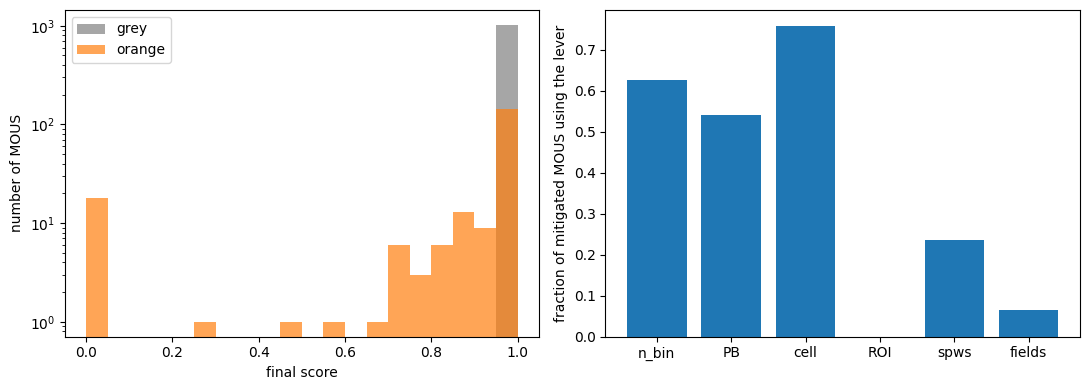

,count,mean,std,min,25%,50%,75%,max
score_n_bin,187.0,0.998,0.002,0.993,0.997,0.998,1.000,1.000
score_PB,187.0,0.995,0.006,0.985,0.989,0.996,1.000,1.000
score_cell,187.0,0.995,0.004,0.990,0.991,0.995,0.998,1.000
score_ROI,187.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000
score_spws,187.0,0.977,0.057,0.714,1.000,1.000,1.000,1.000
score_fields,187.0,0.984,0.077,0.319,1.000,1.000,1.000,1.000
score,187.0,0.950,0.096,0.292,0.970,0.986,0.996,0.999


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 1, 21)
for source, color in [("grey", "grey"), ("orange", "tab:orange")]:
    axes[0].hist(res.loc[res["source"] == source, "score"].dropna(), bins=bins, color=color, alpha=0.7, label=source)
axes[0].set(xlabel="final score", ylabel="number of MOUS", yscale="log")
axes[0].legend()

lever_scores = ["score_n_bin", "score_PB", "score_cell", "score_ROI", "score_spws", "score_fields"]
used = (mitigated[lever_scores] < 1 - 1e-9).mean()
axes[1].bar([c.removeprefix("score_") for c in lever_scores], used)
axes[1].set(ylabel="fraction of mitigated MOUS using the lever")
plt.tight_layout()
plt.show()

mitigated[lever_scores + ["score"]].describe().T.round(3)

### Delivered sizes (the planner's version of Figure 8)

Left: unmitigated sizes of the synthetic MOUSes, coloured by the final score. Right: the delivered (mitigated) sizes.
Failed MOUSes (score 0) are marked with crosses.

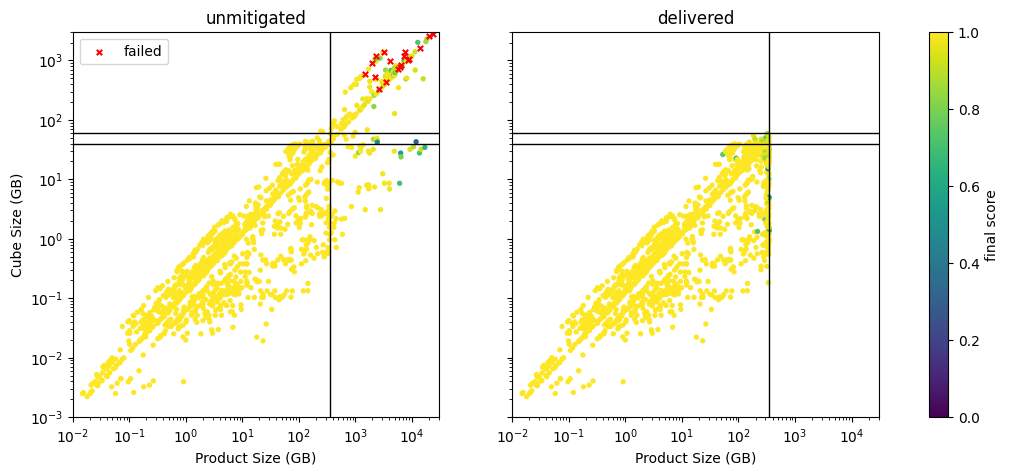

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
ok = res["score"] > 0
for ax, (x, y), title in zip(
    axes,
    [("product_GB", "cube_GB"), ("delivered_product_GB", "delivered_cube_GB")],
    ["unmitigated", "delivered"],
):
    sc = ax.scatter(res.loc[ok, x], res.loc[ok, y], c=res.loc[ok, "score"], s=8, cmap="viridis", vmin=0, vmax=1)
    if title == "unmitigated":
        failed = res["score"] == 0
        ax.scatter(res.loc[failed, x], res.loc[failed, y], marker="x", s=15, color="red", label="failed")
        ax.legend(loc="upper left")
    ax.axhline(limits.maxcubesize, color="k", lw=1)
    ax.axhline(limits.maxcubelimit, color="k", lw=1)
    ax.axvline(limits.maxproductsize, color="k", lw=1)
    ax.set(xscale="log", yscale="log", xlim=(1e-2, 3e4), ylim=(1e-3, 3e3),
           xlabel="Product Size (GB)", title=title)
axes[0].set_ylabel("Cube Size (GB)")
fig.colorbar(sc, ax=axes, label="final score")
plt.show()

### Failures

In [13]:
failed = res[res["outcome"].str.contains("could not")]
print(failed["failure"].value_counts())
failed[["source", "product_GB", "cube_GB", "nspw", "nfields", "repr_nchan", "is_mosaic", "outcome"]].round(2)

failure
cube    18
Name: count, dtype: int64


,source,product_GB,cube_GB,nspw,nfields,repr_nchan,is_mosaic,outcome
91,orange,1485.71,585.02,3,1,960,True,Cube size could not be mitigated
109,orange,1986.20,901.96,4,1,3840,True,Cube size could not be mitigated
120,orange,2246.54,526.02,4,1,1920,True,Cube size could not be mitigated
128,orange,2358.25,1169.98,1,1,128,False,Cube size could not be mitigated
129,orange,2628.32,325.99,1,4,128,True,Cube size could not be mitigated
139,orange,3220.76,1410.07,3,1,7680,False,Cube size could not be mitigated
144,orange,3466.86,430.00,4,1,128,True,Cube size could not be mitigated
154,orange,4015.63,971.03,4,1,3840,True,Cube size could not be mitigated
173,orange,5653.65,705.97,1,4,960,True,Cube size could not be mitigated
175,orange,6129.41,763.00,1,4,240,False,Cube size could not be mitigated


### Runtime

`enumerate_plans()` lists every plan, also when no mitigation is needed; the number of plans grows with the number of
fields times (options + 1) per spw.

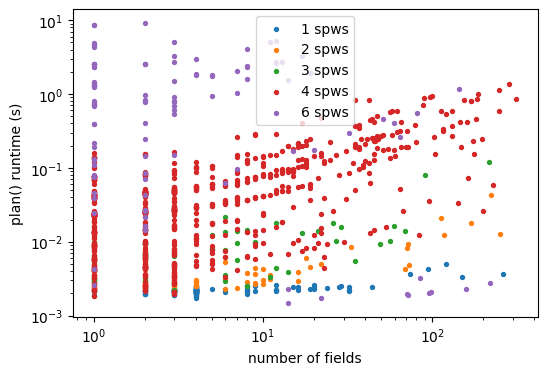

count    1232.000
mean        0.181
std         0.683
min         0.001
25%         0.004
50%         0.024
75%         0.070
max         9.127
Name: runtime_s, dtype: float64


,source,nspw,nfields,error
41,orange,6,84,6123600 plans to enumerate (> max_candidates=1...
53,orange,6,96,7776000 plans to enumerate (> max_candidates=1...
67,orange,6,14,1134000 plans to enumerate (> max_candidates=1...
110,orange,6,72,2916000 plans to enumerate (> max_candidates=1...
206,orange,6,159,3975000 plans to enumerate (> max_candidates=1...
767,grey,6,14,1134000 plans to enumerate (> max_candidates=1...
856,grey,6,98,4410000 plans to enumerate (> max_candidates=1...
935,grey,6,218,17658000 plans to enumerate (> max_candidates=...
967,grey,6,22,5196312 plans to enumerate (> max_candidates=1...
1192,grey,6,71,2875500 plans to enumerate (> max_candidates=1...


In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
for nspw, d in res.groupby("nspw"):
    ax.scatter(d["nfields"], d["runtime_s"], s=8, label=f"{nspw} spws")
ax.set(xscale="log", yscale="log", xlabel="number of fields", ylabel="plan() runtime (s)")
ax.legend()
plt.show()

print(res["runtime_s"].describe().round(3))
res.loc[res["outcome"] == "error", ["source", "nspw", "nfields", "error"]]

## 5. Findings (SEED = 42, default priors and weights; PB level 0.2 and 5 ppb, the pipeline defaults)

* **No mitigation needed:** 1015 of 1025 grey MOUSes. 5 were mitigated slightly, because the rounded field count puts their product just above 350 GB. 5 ran into the plan limit (below).
* **Orange MOUSes** (mitigated in Cycle 7): 182 mitigated, 2 not mitigated, 18 failures (9 %), 5 errors.
  * All failures are cube failures: the representative spw cannot get under `maxcubelimit` = 60 GB.
  * The cube levers remove at most a factor of about 25 for single pointings (n_bin 0.5 × PB 0.22 × cell 0.36), but only about 5.5 for mosaics, which have no PB lever. 12 of the 18 failures are mosaics; the 6 single pointings have largest cubes of about 760-1400 GB.
  * The original pipeline also stops with an error when the representative spw stays above `maxcubelimit`. 9 % is the same fraction of mitigated MOUSes whose limits were lifted in Cycle 7 (memo).
  * Before the PB fix (PB treated as a size to be lowered to 0.7), 47 of the orange MOUSes (23 %) failed.
* **Mitigation types:**
  * The planner prefers the cube levers (weight 100, scores ≥ 0.98), so "cube size" alone is used about three times as often as in the memo (75 % vs. 24 %), and "cube size + spws" much less (18 % vs. 46 %).
  * "spws + fields" (22 % in the memo) never occurs: fields are only removed together with cube levers.
* **Final score:** median 0.99 for the mitigated MOUSes. Low scores come from removing spws or fields. The cube-lever scores stay ≥ 0.98.
* **Runtime:** median 24 ms per MOUS, up to about 9 s.
  * All MOUSes are enumerated in full, even when no mitigation is needed.
  * 10 MOUSes (all with 6 spws) exceed `max_candidates` = 1,000,000 plans and raise an error.
